# Task 3: Neural Network Classifier on CIFAR-10

This task builds a multi-class neural network classifier for the CIFAR-10
dataset, which contains 32 × 32 RGB images from ten mutually exclusive
classes.

Each image is converted to floating-point pixel values in the range [0, 1]
and flattened into a 3,072-dimensional input vector for use with a fully
connected neural network.

Several network architectures will be compared by varying the number of
hidden layers and neurons per layer. Shallow, wide networks will be compared
with deeper, narrower networks. Regularization will then be evaluated by
comparing training and validation loss.

The best-performing model will finally be evaluated on the untouched test
set using classification accuracy, cross-entropy loss, and a confusion
matrix.

## 1. Setup and Reproducibility

Required libraries are imported and a fixed random seed is used so that
dataset splitting and model initialization are reproducible.

In [3]:
# Core utilities
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use a GPU if one is available; otherwise use the CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


## 2. Load and Preprocess CIFAR-10

The CIFAR-10 images are converted to PyTorch tensors using
`transforms.ToTensor()`. This converts the original pixel values to
floating-point values in the range [0, 1].

Each RGB image originally has shape `(3, 32, 32)`. The image is flattened
into a one-dimensional vector containing 3,072 features so that it can be
used as input to a fully connected neural network.

The official CIFAR-10 test set is kept separate and will only be used for
the final evaluation.

In [4]:
from pathlib import Path

# Locate the repository's data directory.
# This works whether the notebook kernel starts inside the repository
# root or inside the notebooks folder.
if Path.cwd().name == "notebooks":
    DATA_DIR = Path("../data").resolve()
else:
    DATA_DIR = Path("./data").resolve()

print("Data directory:", DATA_DIR)

# Convert images to tensors with pixel values in [0, 1]
# and flatten each 3 x 32 x 32 image into 3,072 features.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda image: torch.flatten(image))
])

# Load the 50,000-image CIFAR-10 training set.
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=transform
)

# Load the official 10,000-image CIFAR-10 test set.
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=transform
)

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Full training samples:", len(full_train_dataset))
print("Test samples:", len(test_dataset))

Data directory: C:\Users\priya\OneDrive\Documents\cap5610-midterm\data


C:\Users\priya\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Full training samples: 50000
Test samples: 10000


## 3. Create Training and Validation Sets

The original CIFAR-10 training set contains 50,000 images.

To compare network architectures without using the test set, the training
data is divided into 45,000 training examples and 5,000 validation examples.

The validation set is used for model selection and regularization
experiments. The official 10,000-image test set remains untouched until the
final evaluation.

In [5]:
# Split the original 50,000-image training set into
# 45,000 training samples and 5,000 validation samples.
train_size = 45_000
val_size = 5_000

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=split_generator
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


## 4. Create DataLoaders and Verify Preprocessing

The training, validation, and test datasets are grouped into mini-batches
for efficient model training and evaluation.

A batch size of 256 is used. The training data is shuffled between epochs,
while the validation and test sets are kept in a fixed order.

One batch is inspected to confirm that each image has been flattened into
3,072 input features and that all pixel values remain within the required
range [0, 1].

In [6]:
# Batch size used throughout the experiments.
BATCH_SIZE = 256

# Create mini-batch data loaders.
# num_workers=0 is used for reliable execution in Windows/Jupyter.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Inspect one training batch to verify preprocessing.
sample_inputs, sample_labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("Batch input shape:", sample_inputs.shape)
print("Batch label shape:", sample_labels.shape)

print("Minimum pixel value:", sample_inputs.min().item())
print("Maximum pixel value:", sample_inputs.max().item())

Training batches: 176
Validation batches: 20
Test batches: 40
Batch input shape: torch.Size([256, 3072])
Batch label shape: torch.Size([256])
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 5. Local Training Speed Check

Before running the full architecture comparison, a small two-hidden-layer
network is trained for one epoch to estimate local CPU training time.

This benchmark is used only to determine whether the complete set of
experiments can be run efficiently on the local machine.

In [7]:
# Small representative network used only for timing.
benchmark_model = nn.Sequential(
    nn.Linear(3072, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# Cross-entropy loss is appropriate for multi-class classification.
criterion = nn.CrossEntropyLoss()

# Adam optimizer with a standard learning rate.
optimizer = optim.Adam(
    benchmark_model.parameters(),
    lr=0.001
)

benchmark_model.train()

start_time = time.perf_counter()

running_loss = 0.0
correct_predictions = 0
total_samples = 0

for inputs, labels in train_loader:
    inputs = inputs.to(device)
    labels = labels.to(device)

    # Clear gradients from the previous batch.
    optimizer.zero_grad()

    # Forward pass.
    outputs = benchmark_model(inputs)

    # Compute classification loss.
    loss = criterion(outputs, labels)

    # Backpropagation and parameter update.
    loss.backward()
    optimizer.step()

    # Accumulate loss.
    running_loss += loss.item() * inputs.size(0)

    # Compute training accuracy for this epoch.
    predictions = outputs.argmax(dim=1)
    correct_predictions += (predictions == labels).sum().item()
    total_samples += labels.size(0)

epoch_time = time.perf_counter() - start_time

average_loss = running_loss / total_samples
training_accuracy = correct_predictions / total_samples

print(f"One epoch time: {epoch_time:.2f} seconds")
print(f"Training loss: {average_loss:.4f}")
print(f"Training accuracy: {training_accuracy:.4f}")

One epoch time: 9.00 seconds
Training loss: 1.9172
Training accuracy: 0.3082


## 6. Flexible Neural Network Architecture

A flexible fully connected neural network is defined so that both the number
of hidden layers and the number of neurons in each layer can be varied.

ReLU activation is used after each hidden layer. The output layer contains
10 neurons, one for each CIFAR-10 class.

The model returns raw output scores (logits). A softmax layer is not added
explicitly because PyTorch's `CrossEntropyLoss` applies the required
log-softmax operation internally.

The same model definition will later also allow dropout to be introduced
without changing the underlying architecture.

In [8]:
class FlexibleMLP(nn.Module):
    """
    Fully connected neural network with a configurable
    number of hidden layers and neurons per layer.
    """

    def __init__(self, hidden_sizes, dropout_rate=0.0):
        super().__init__()

        layers = []

        # Each flattened CIFAR-10 image has 3,072 input features.
        input_size = 3072

        # Add each hidden layer requested in hidden_sizes.
        for hidden_size in hidden_sizes:

            # Fully connected layer.
            layers.append(
                nn.Linear(input_size, hidden_size)
            )

            # Non-linear activation.
            layers.append(
                nn.ReLU()
            )

            # Dropout is optional and will be used later
            # for the regularization experiment.
            if dropout_rate > 0:
                layers.append(
                    nn.Dropout(dropout_rate)
                )

            # The output size of this layer becomes the
            # input size of the next layer.
            input_size = hidden_size

        # Final classification layer:
        # one output score for each of the 10 classes.
        layers.append(
            nn.Linear(input_size, 10)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    """Return the number of trainable model parameters."""
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

In [9]:
# Create a two-hidden-layer example to verify
# that the flexible model is working correctly.
example_model = FlexibleMLP(
    hidden_sizes=[128, 128]
).to(device)

print(example_model)

print(
    "\nTrainable parameters:",
    f"{count_parameters(example_model):,}"
)

# Verify that one batch produces 10 class scores per image.
with torch.no_grad():
    example_outputs = example_model(
        sample_inputs.to(device)
    )

print("Output shape:", example_outputs.shape)

FlexibleMLP(
  (network): Sequential(
    (0): Linear(in_features=3072, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Trainable parameters: 411,146
Output shape: torch.Size([256, 10])


## 7. Training and Evaluation Functions

Reusable functions are defined to train and evaluate each network under the
same conditions.

For each epoch, cross-entropy loss and classification accuracy are measured
on both the training and validation sets. Training time is also recorded so
that the computational cost of different network architectures can be
compared.

The validation data is used only for model comparison and is never used to
update the model parameters.

In [10]:
def train_one_epoch(model, loader, criterion, optimizer):
    """
    Train the model for one complete epoch.

    Returns
    -------
    average_loss : float
        Mean cross-entropy loss over the training set.
    accuracy : float
        Fraction of correctly classified training examples.
    """

    model.train()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Remove gradients left from the previous batch.
        optimizer.zero_grad()

        # Forward pass.
        outputs = model(inputs)

        # Compute cross-entropy loss.
        loss = criterion(outputs, labels)

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        optimizer.step()

        # Accumulate loss weighted by batch size.
        total_loss += loss.item() * inputs.size(0)

        # Determine the predicted class.
        predictions = outputs.argmax(dim=1)

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples

    return average_loss, accuracy

In [11]:
def evaluate_model(model, loader, criterion):
    """
    Evaluate the model without updating its parameters.

    Returns
    -------
    average_loss : float
        Mean cross-entropy loss over the dataset.
    accuracy : float
        Fraction of correctly classified examples.
    """

    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Gradients are unnecessary during evaluation.
    with torch.no_grad():

        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Forward pass only.
            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += labels.size(0)

    average_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples

    return average_loss, accuracy

In [12]:
def train_model(
    hidden_sizes,
    epochs=15,
    dropout_rate=0.0,
    learning_rate=0.001
):
    """
    Create and train one FlexibleMLP architecture.

    Returns the trained model, epoch-by-epoch history,
    and total training time.
    """

    # Reset the random seed so architecture comparisons
    # are as reproducible as possible.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    # Create the requested network.
    model = FlexibleMLP(
        hidden_sizes=hidden_sizes,
        dropout_rate=dropout_rate
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):

        # Train for one epoch.
        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        # Evaluate on the validation set.
        val_loss, val_accuracy = evaluate_model(
            model,
            val_loader,
            criterion
        )

        # Store the results.
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

    total_time = time.perf_counter() - start_time

    return model, history, total_time

## 8. Architecture Comparison: Depth and Width

Four fully connected neural network architectures are compared while keeping
the optimizer, learning rate, batch size, number of epochs, activation
function, and training/validation split fixed.

The architectures are chosen to compare both network depth and width:

- a shallow, narrow network with one hidden layer of 128 neurons,
- a shallow, wide network with one hidden layer of 512 neurons,
- a medium-depth network with hidden layers of 256 and 128 neurons,
- a deep, narrow network with four hidden layers of 128 neurons each.

No regularization is applied during this stage so that the effect of network
architecture and model capacity can be examined independently.

Each architecture is trained for 15 epochs. Training time, training loss,
validation loss, and validation accuracy are recorded for comparison.

In [13]:
# Architectures used for the controlled comparison.
architectures = {
    "Shallow-Narrow": [128],
    "Shallow-Wide": [512],
    "Medium": [256, 128],
    "Deep-Narrow": [128, 128, 128, 128]
}

EPOCHS = 15

# Store trained models, full learning histories,
# and summary statistics for later analysis.
architecture_models = {}
architecture_histories = {}
architecture_results = []

for model_name, hidden_sizes in architectures.items():

    print("\n" + "=" * 70)
    print(f"Training: {model_name}")
    print(f"Hidden layers: {hidden_sizes}")
    print("=" * 70)

    # Train without regularization so that architecture
    # is the main experimental variable.
    model, history, training_time = train_model(
        hidden_sizes=hidden_sizes,
        epochs=EPOCHS,
        dropout_rate=0.0,
        learning_rate=0.001
    )

    architecture_models[model_name] = model
    architecture_histories[model_name] = history

    # Find the epoch that achieved the highest
    # validation accuracy.
    best_epoch_index = int(
        np.argmax(history["val_accuracy"])
    )

    best_epoch = best_epoch_index + 1

    # Record summary information for this architecture.
    architecture_results.append({
        "Model": model_name,
        "Hidden Layers": str(hidden_sizes),
        "Parameters": count_parameters(model),
        "Training Time (s)": training_time,
        "Best Epoch": best_epoch,
        "Best Val Accuracy": history["val_accuracy"][best_epoch_index],
        "Val Loss at Best Epoch": history["val_loss"][best_epoch_index],
        "Final Train Loss": history["train_loss"][-1],
        "Final Val Loss": history["val_loss"][-1]
    })


Training: Shallow-Narrow
Hidden layers: [128]
Epoch 01/15 | Train Loss: 1.9133 | Train Acc: 0.3171 | Val Loss: 1.8121 | Val Acc: 0.3662
Epoch 02/15 | Train Loss: 1.7556 | Train Acc: 0.3792 | Val Loss: 1.7373 | Val Acc: 0.3834
Epoch 03/15 | Train Loss: 1.6817 | Train Acc: 0.4057 | Val Loss: 1.6556 | Val Acc: 0.4192
Epoch 04/15 | Train Loss: 1.6247 | Train Acc: 0.4274 | Val Loss: 1.6636 | Val Acc: 0.4102
Epoch 05/15 | Train Loss: 1.5878 | Train Acc: 0.4401 | Val Loss: 1.5939 | Val Acc: 0.4382
Epoch 06/15 | Train Loss: 1.5596 | Train Acc: 0.4512 | Val Loss: 1.5908 | Val Acc: 0.4372
Epoch 07/15 | Train Loss: 1.5400 | Train Acc: 0.4561 | Val Loss: 1.5810 | Val Acc: 0.4430
Epoch 08/15 | Train Loss: 1.5163 | Train Acc: 0.4668 | Val Loss: 1.5308 | Val Acc: 0.4614
Epoch 09/15 | Train Loss: 1.5044 | Train Acc: 0.4695 | Val Loss: 1.5493 | Val Acc: 0.4586
Epoch 10/15 | Train Loss: 1.4813 | Train Acc: 0.4780 | Val Loss: 1.5226 | Val Acc: 0.4634
Epoch 11/15 | Train Loss: 1.4711 | Train Acc: 0.4810 

In [14]:
# Convert the architecture results into a table
# for easier comparison.
architecture_results_df = pd.DataFrame(
    architecture_results
)

# Sort by the best validation accuracy.
architecture_results_df = architecture_results_df.sort_values(
    by="Best Val Accuracy",
    ascending=False
).reset_index(drop=True)

architecture_results_df

,Model,Hidden Layers,Parameters,Training Time (s),Best Epoch,Best Val Accuracy,Val Loss at Best Epoch,Final Train Loss,Final Val Loss
0,Medium,"[256, 128]",820874,188.930945,14,0.5132,1.392225,1.279443,1.407457
1,Deep-Narrow,"[128, 128, 128, 128]",444170,162.782670,14,0.4956,1.415329,1.309993,1.443722
2,Shallow-Wide,[512],1578506,246.214794,13,0.4910,1.465821,1.350548,1.456907
3,Shallow-Narrow,[128],394634,149.811818,15,0.4836,1.480444,1.425670,1.480444


### Architecture Comparison Results

The medium architecture with hidden layers `[256, 128]` achieved the best
validation accuracy of 0.5132, reaching its best result at epoch 14.

Increasing model capacity did not produce a monotonic improvement in
validation performance. The shallow-wide model contained the largest number
of trainable parameters (1,578,506) but achieved a lower best validation
accuracy of 0.4910. Similarly, the deeper four-layer network reached a best
validation accuracy of 0.4956.

The shallow-narrow network had the lowest model capacity and obtained the
lowest validation accuracy of 0.4836.

Training time also increased as the models became larger or more complex.
The medium architecture therefore provided the strongest balance between
model capacity, training time, and validation performance and was selected
for the regularization experiment.

## 9. Regularization with Dropout

The medium architecture `[256, 128]` produced the highest validation accuracy
in the architecture comparison and is therefore used for the regularization
experiment.

Dropout is applied after each hidden layer to reduce overfitting by randomly
deactivating a fraction of hidden neurons during training.

A dropout rate of 0.30 is tested while keeping the architecture, optimizer,
learning rate, batch size, and number of training epochs unchanged. The
regularized model is compared with the unregularized medium network using
training loss, validation loss, validation accuracy, and the gap between
training and validation loss.

## 10. Final Model Training

The architecture and training duration are selected using only the training
and validation data.

The `[256, 128]` architecture achieved the highest validation accuracy, with
its best result occurring at epoch 14. After model selection, a new model is
trained for 14 epochs using all 50,000 CIFAR-10 training images.

The official test set remains untouched during this stage and is used only
for the final evaluation.

In [15]:
# Train the same medium architecture with dropout regularization.
dropout_model, dropout_history, dropout_training_time = train_model(
    hidden_sizes=[256, 128],
    epochs=15,
    dropout_rate=0.30,
    learning_rate=0.001
)

# Retrieve the previously trained unregularized medium model results.
medium_history = architecture_histories["Medium"]

# Compute the final train-validation loss gap for both models.
unregularized_gap = (
    medium_history["val_loss"][-1]
    - medium_history["train_loss"][-1]
)

dropout_gap = (
    dropout_history["val_loss"][-1]
    - dropout_history["train_loss"][-1]
)

# Find the best validation accuracy obtained by the dropout model.
dropout_best_epoch_index = int(
    np.argmax(dropout_history["val_accuracy"])
)

dropout_best_epoch = dropout_best_epoch_index + 1

print("Unregularized Medium Model")
print(
    f"Final Train Loss: {medium_history['train_loss'][-1]:.4f}"
)
print(
    f"Final Val Loss:   {medium_history['val_loss'][-1]:.4f}"
)
print(
    f"Loss Gap:         {unregularized_gap:.4f}"
)

print("\nDropout-Regularized Medium Model")
print(
    f"Final Train Loss: {dropout_history['train_loss'][-1]:.4f}"
)
print(
    f"Final Val Loss:   {dropout_history['val_loss'][-1]:.4f}"
)
print(
    f"Loss Gap:         {dropout_gap:.4f}"
)
print(
    f"Best Val Accuracy: "
    f"{dropout_history['val_accuracy'][dropout_best_epoch_index]:.4f}"
)
print(
    f"Best Epoch: {dropout_best_epoch}"
)
print(
    f"Training Time: {dropout_training_time:.2f} seconds"
)

Epoch 01/15 | Train Loss: 2.0080 | Train Acc: 0.2618 | Val Loss: 1.8424 | Val Acc: 0.3458
Epoch 02/15 | Train Loss: 1.8460 | Train Acc: 0.3337 | Val Loss: 1.7603 | Val Acc: 0.3738
Epoch 03/15 | Train Loss: 1.7921 | Train Acc: 0.3569 | Val Loss: 1.6990 | Val Acc: 0.3948
Epoch 04/15 | Train Loss: 1.7485 | Train Acc: 0.3773 | Val Loss: 1.6592 | Val Acc: 0.4036
Epoch 05/15 | Train Loss: 1.7235 | Train Acc: 0.3846 | Val Loss: 1.6593 | Val Acc: 0.4076
Epoch 06/15 | Train Loss: 1.6993 | Train Acc: 0.3929 | Val Loss: 1.6317 | Val Acc: 0.4184
Epoch 07/15 | Train Loss: 1.6896 | Train Acc: 0.3972 | Val Loss: 1.6182 | Val Acc: 0.4354
Epoch 08/15 | Train Loss: 1.6746 | Train Acc: 0.4011 | Val Loss: 1.5919 | Val Acc: 0.4408
Epoch 09/15 | Train Loss: 1.6479 | Train Acc: 0.4090 | Val Loss: 1.5826 | Val Acc: 0.4402
Epoch 10/15 | Train Loss: 1.6425 | Train Acc: 0.4101 | Val Loss: 1.5531 | Val Acc: 0.4496
Epoch 11/15 | Train Loss: 1.6172 | Train Acc: 0.4203 | Val Loss: 1.5515 | Val Acc: 0.4524
Epoch 12/1

### Fair Comparison of the Regularization Gap

During training, dropout is active and therefore artificially increases the
observed training loss. During validation, dropout is disabled.

To compare the training-validation loss gap fairly, both the training and
validation sets are therefore evaluated after training with the models in
evaluation mode. This ensures that dropout is disabled for both measurements.

In [16]:
# Evaluate both models under identical evaluation conditions.
criterion = nn.CrossEntropyLoss()

# Unregularized medium model.
unregularized_model = architecture_models["Medium"]

unreg_train_loss, unreg_train_accuracy = evaluate_model(
    unregularized_model,
    train_loader,
    criterion
)

unreg_val_loss, unreg_val_accuracy = evaluate_model(
    unregularized_model,
    val_loader,
    criterion
)

# Dropout-regularized model.
dropout_train_loss, dropout_train_accuracy = evaluate_model(
    dropout_model,
    train_loader,
    criterion
)

dropout_val_loss, dropout_val_accuracy = evaluate_model(
    dropout_model,
    val_loader,
    criterion
)

# Evaluation-mode generalization gaps.
unreg_gap = unreg_val_loss - unreg_train_loss
dropout_gap = dropout_val_loss - dropout_train_loss

print("Unregularized Medium Model")
print(f"Train Loss: {unreg_train_loss:.4f}")
print(f"Val Loss:   {unreg_val_loss:.4f}")
print(f"Loss Gap:   {unreg_gap:.4f}")
print(f"Val Acc:    {unreg_val_accuracy:.4f}")

print("\nDropout 0.30 Medium Model")
print(f"Train Loss: {dropout_train_loss:.4f}")
print(f"Val Loss:   {dropout_val_loss:.4f}")
print(f"Loss Gap:   {dropout_gap:.4f}")
print(f"Val Acc:    {dropout_val_accuracy:.4f}")

Unregularized Medium Model
Train Loss: 1.2619
Val Loss:   1.4075
Loss Gap:   0.1455
Val Acc:    0.5048

Dropout 0.30 Medium Model
Train Loss: 1.4775
Val Loss:   1.5342
Loss Gap:   0.0567
Val Acc:    0.4550


### Lower Dropout Rate

A dropout rate of 0.30 substantially reduced the training-validation loss
gap, but validation accuracy also decreased considerably. This suggests that
the model was over-regularized.

A lower dropout rate of 0.10 is therefore tested using the same architecture
and training settings to determine whether a better balance between
generalization and predictive performance can be achieved.

In [18]:
# Train the same medium architecture using a milder dropout rate.
dropout_10_model, dropout_10_history, dropout_10_training_time = train_model(
    hidden_sizes=[256, 128],
    epochs=15,
    dropout_rate=0.10,
    learning_rate=0.001
)

# Evaluate the regularized model with dropout disabled,
# just as it would be during validation or testing.
dropout_10_train_loss, dropout_10_train_accuracy = evaluate_model(
    dropout_10_model,
    train_loader,
    criterion
)

dropout_10_val_loss, dropout_10_val_accuracy = evaluate_model(
    dropout_10_model,
    val_loader,
    criterion
)

dropout_10_gap = (
    dropout_10_val_loss - dropout_10_train_loss
)

# Find the best validation accuracy achieved during training.
dropout_10_best_epoch_index = int(
    np.argmax(dropout_10_history["val_accuracy"])
)

dropout_10_best_epoch = (
    dropout_10_best_epoch_index + 1
)

dropout_10_best_accuracy = (
    dropout_10_history["val_accuracy"][
        dropout_10_best_epoch_index
    ]
)

print("Dropout 0.10 Medium Model")
print(f"Train Loss:        {dropout_10_train_loss:.4f}")
print(f"Val Loss:          {dropout_10_val_loss:.4f}")
print(f"Loss Gap:          {dropout_10_gap:.4f}")
print(f"Final Val Acc:     {dropout_10_val_accuracy:.4f}")
print(f"Best Val Acc:      {dropout_10_best_accuracy:.4f}")
print(f"Best Epoch:        {dropout_10_best_epoch}")
print(
    f"Training Time:     "
    f"{dropout_10_training_time:.2f} seconds"
)

Epoch 01/15 | Train Loss: 1.9381 | Train Acc: 0.2887 | Val Loss: 1.8038 | Val Acc: 0.3512
Epoch 02/15 | Train Loss: 1.7556 | Train Acc: 0.3727 | Val Loss: 1.6799 | Val Acc: 0.3972
Epoch 03/15 | Train Loss: 1.6829 | Train Acc: 0.3986 | Val Loss: 1.6226 | Val Acc: 0.4200
Epoch 04/15 | Train Loss: 1.6281 | Train Acc: 0.4206 | Val Loss: 1.5888 | Val Acc: 0.4374
Epoch 05/15 | Train Loss: 1.5867 | Train Acc: 0.4335 | Val Loss: 1.5529 | Val Acc: 0.4448
Epoch 06/15 | Train Loss: 1.5568 | Train Acc: 0.4463 | Val Loss: 1.5204 | Val Acc: 0.4574
Epoch 07/15 | Train Loss: 1.5293 | Train Acc: 0.4574 | Val Loss: 1.5150 | Val Acc: 0.4538
Epoch 08/15 | Train Loss: 1.5084 | Train Acc: 0.4584 | Val Loss: 1.4810 | Val Acc: 0.4758
Epoch 09/15 | Train Loss: 1.4820 | Train Acc: 0.4719 | Val Loss: 1.4817 | Val Acc: 0.4734
Epoch 10/15 | Train Loss: 1.4716 | Train Acc: 0.4756 | Val Loss: 1.4508 | Val Acc: 0.4840
Epoch 11/15 | Train Loss: 1.4519 | Train Acc: 0.4829 | Val Loss: 1.4740 | Val Acc: 0.4846
Epoch 12/1

### Regularization Results

Dropout successfully reduced the difference between training and validation
loss, indicating that it reduced overfitting.

Without dropout, the evaluation-mode training-validation loss gap was 0.1455.
Using a dropout rate of 0.10 reduced this gap to 0.0998, while a dropout rate
of 0.30 reduced it further to 0.0567.

However, the reduction in the loss gap came at the cost of classification
performance. The unregularized medium network achieved the highest validation
accuracy of 0.5132. Dropout rates of 0.10 and 0.30 achieved best validation
accuracies of 0.4970 and 0.4606, respectively.

Therefore, dropout reduced overfitting but also introduced underfitting,
particularly at the higher dropout rate. The unregularized `[256, 128]`
architecture was retained as the final model because it produced the strongest
validation performance.

In [19]:
# Use all 50,000 available training images for the final model.
full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# Reset random seeds before final training.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Best architecture selected from the validation experiments.
final_model = FlexibleMLP(
    hidden_sizes=[256, 128],
    dropout_rate=0.0
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.001
)

FINAL_EPOCHS = 14

final_training_history = []

start_time = time.perf_counter()

for epoch in range(1, FINAL_EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        final_model,
        full_train_loader,
        criterion,
        optimizer
    )

    final_training_history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Train Accuracy": train_accuracy
    })

    print(
        f"Epoch {epoch:02d}/{FINAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f}"
    )

final_training_time = time.perf_counter() - start_time

print(
    f"\nFinal training time: "
    f"{final_training_time:.2f} seconds"
)

Epoch 01/14 | Train Loss: 1.9143 | Train Acc: 0.3044
Epoch 02/14 | Train Loss: 1.7050 | Train Acc: 0.3877
Epoch 03/14 | Train Loss: 1.6246 | Train Acc: 0.4183
Epoch 04/14 | Train Loss: 1.5616 | Train Acc: 0.4429
Epoch 05/14 | Train Loss: 1.5152 | Train Acc: 0.4619
Epoch 06/14 | Train Loss: 1.4838 | Train Acc: 0.4728
Epoch 07/14 | Train Loss: 1.4431 | Train Acc: 0.4872
Epoch 08/14 | Train Loss: 1.4206 | Train Acc: 0.4946
Epoch 09/14 | Train Loss: 1.3948 | Train Acc: 0.5033
Epoch 10/14 | Train Loss: 1.3772 | Train Acc: 0.5088
Epoch 11/14 | Train Loss: 1.3490 | Train Acc: 0.5191
Epoch 12/14 | Train Loss: 1.3219 | Train Acc: 0.5291
Epoch 13/14 | Train Loss: 1.3071 | Train Acc: 0.5340
Epoch 14/14 | Train Loss: 1.2952 | Train Acc: 0.5390

Final training time: 164.18 seconds


## 11. Final Test-Set Evaluation

The final model is evaluated once on the untouched CIFAR-10 test set.

Overall classification accuracy and mean cross-entropy loss are reported.
A confusion matrix is also generated to examine which image categories are
most frequently confused by the network.

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Evaluate the final model on the untouched test set.
final_model.eval()

test_loss_total = 0.0
test_correct = 0
test_total = 0

all_true_labels = []
all_predictions = []

with torch.no_grad():

    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = final_model(inputs)

        loss = criterion(outputs, labels)

        # Accumulate cross-entropy loss.
        test_loss_total += (
            loss.item() * inputs.size(0)
        )

        # Predicted class is the class with the largest logit.
        predictions = outputs.argmax(dim=1)

        test_correct += (
            predictions == labels
        ).sum().item()

        test_total += labels.size(0)

        # Store labels for the confusion matrix.
        all_true_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

# Overall test metrics.
test_loss = test_loss_total / test_total
test_accuracy = test_correct / test_total

print(f"Test Cross-Entropy Loss: {test_loss:.4f}")
print(f"Test Accuracy:           {test_accuracy:.4f}")
print(f"Test Accuracy (%):       {100 * test_accuracy:.2f}%")

Test Cross-Entropy Loss: 1.3969
Test Accuracy:           0.5075
Test Accuracy (%):       50.75%


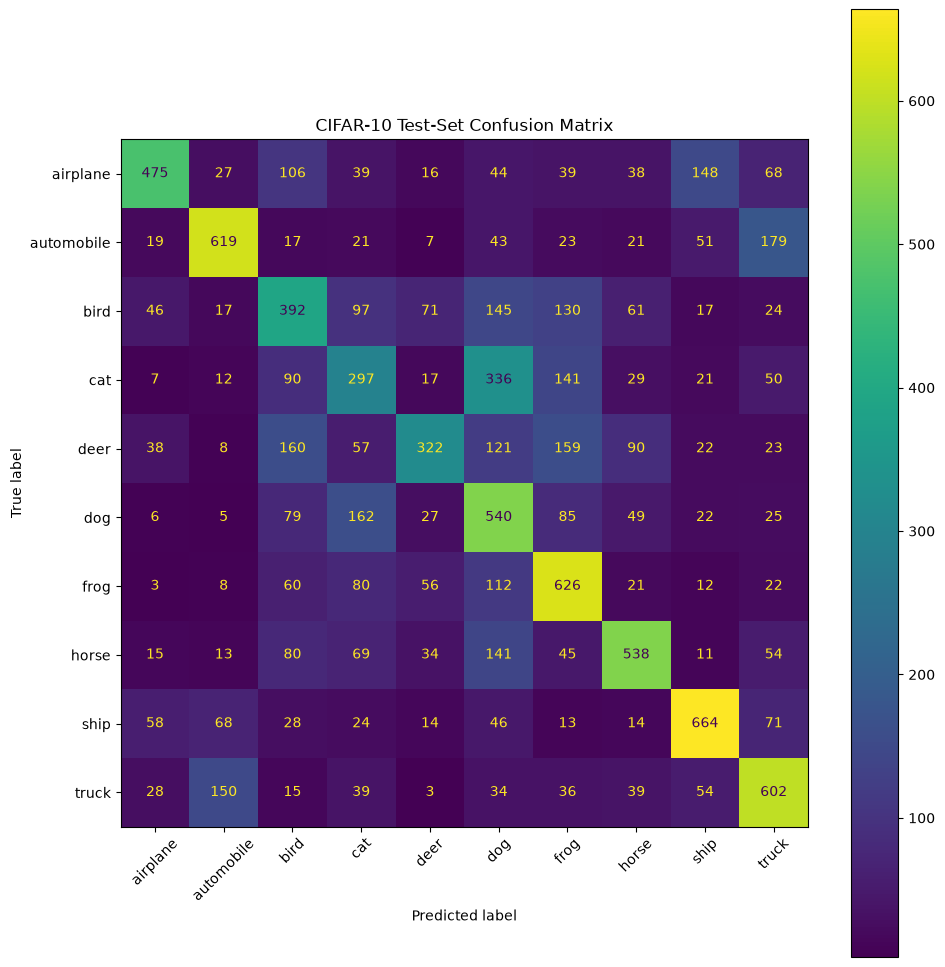

Most frequent confusion: cat → dog
Number of such errors: 336


In [21]:
# Construct the confusion matrix.
cm = confusion_matrix(
    all_true_labels,
    all_predictions
)

# Display the confusion matrix using the CIFAR-10 class names.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

display.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("CIFAR-10 Test-Set Confusion Matrix")
plt.tight_layout()
plt.show()

# Find the largest off-diagonal value to identify
# the most frequent directed class confusion.
off_diagonal_cm = cm.copy()
np.fill_diagonal(off_diagonal_cm, 0)

true_class_index, predicted_class_index = np.unravel_index(
    np.argmax(off_diagonal_cm),
    off_diagonal_cm.shape
)

print(
    "Most frequent confusion:",
    class_names[true_class_index],
    "→",
    class_names[predicted_class_index]
)

print(
    "Number of such errors:",
    off_diagonal_cm[
        true_class_index,
        predicted_class_index
    ]
)

## 12. Conclusion

A series of fully connected neural networks was evaluated on the CIFAR-10
classification task after flattening each image into 3,072 features and
scaling all pixel values to the range [0, 1].

Among the tested architectures, the two-hidden-layer network `[256, 128]`
provided the strongest validation performance, reaching a best validation
accuracy of 0.5132. Increasing network capacity did not consistently improve
performance. In particular, the much wider 512-neuron model contained the
largest number of parameters but achieved lower validation accuracy, while
the four-layer narrow network also performed below the selected medium model.

Dropout reduced the training-validation loss gap. The gap decreased from
0.1455 without dropout to 0.0998 with a dropout rate of 0.10 and 0.0567 with
a dropout rate of 0.30. However, both dropout settings reduced validation
accuracy, indicating increasing underfitting as the regularization strength
increased. Therefore, the unregularized `[256, 128]` network was retained for
the final model.

After retraining the selected architecture on all 50,000 training images for
14 epochs, the model achieved a test accuracy of 50.75% and a test
cross-entropy loss of 1.3969. The confusion matrix showed that the most
frequent classification error was predicting dogs for cat images, occurring
336 times.

Overall, moderate network depth and width provided a better trade-off than
either a very wide shallow network or a deeper narrow network for this
flattened CIFAR-10 representation.